<a href="https://colab.research.google.com/github/melissaboukerchi55-create/principe_de_programmation/blob/main/Projet_Immobilier_complet.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Projet Prix immobiliers

**Le but :** prédire le **prix** des logements d'un quartier de Californie, à partir de ses caractéristiques (revenu, âge des logements, proximité de l'océan…).

C'est une **régression** : on prédit un **nombre** (un prix), et pas une catégorie.

**Pour lancer :** menu **Exécution** → **Tout exécuter**. Ça prend environ 1 minute, sans GPU.

## 1. Les données : 20 640 quartiers
- **1 ligne = 1 quartier.**
- **Les colonnes = les informations** sur le quartier.
- **La colonne `median_house_value` = le prix.** C'est le **y**, ce qu'on veut deviner.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
pd.set_option("display.max_columns", None)   # afficher toutes les colonnes

url = "https://raw.githubusercontent.com/ageron/handson-ml2/master/datasets/housing/housing.csv"
donnees = pd.read_csv(url)
print("Taille du tableau :", donnees.shape)
donnees.head(3)

Taille du tableau : (20640, 10)


,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY


## 2. L'exploration : regarder les données avant le modèle
On cherche **3 découvertes** :
1. le **revenu** est la colonne la plus liée au prix ;
2. près de l'**océan**, c'est plus cher ;
3. les prix sont **bloqués à 500 001 $**.

Lien de chaque colonne avec le prix (corrélation) :
median_house_value    1.00
median_income         0.69
total_rooms           0.13
housing_median_age    0.11
households            0.07
total_bedrooms        0.05
population           -0.02
longitude            -0.05
latitude             -0.14
Name: median_house_value, dtype: float64

Prix moyen selon la proximité de l'océan :
ocean_proximity
<1H OCEAN     240084.0
INLAND        124805.0
ISLAND        380440.0
NEAR BAY      259212.0
NEAR OCEAN    249434.0
Name: median_house_value, dtype: float64

Quartiers bloqués à 500 001 $ : 965


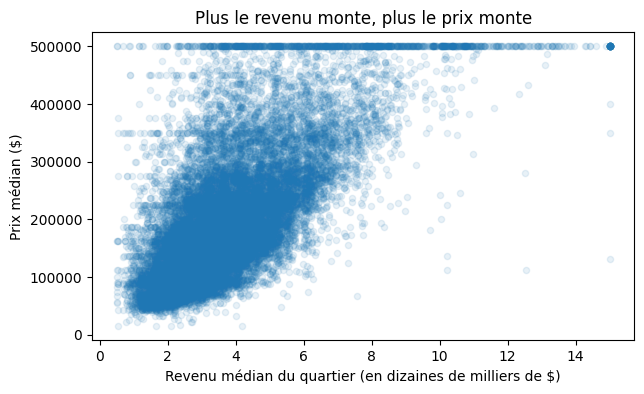

In [2]:
# Découverte 1 : le revenu est la colonne la plus liée au prix
print("Lien de chaque colonne avec le prix (corrélation) :")
print(donnees.corr(numeric_only=True)["median_house_value"].sort_values(ascending=False).round(2))

# Découverte 2 : près de l'océan, c'est plus cher
print("\nPrix moyen selon la proximité de l'océan :")
print(donnees.groupby("ocean_proximity")["median_house_value"].mean().round(0))

# Découverte 3 : les prix sont bloqués à 500 001 $
print("\nQuartiers bloqués à 500 001 $ :", (donnees["median_house_value"] == 500001).sum())

# Le dessin : revenu et prix
donnees.plot.scatter(x="median_income", y="median_house_value", alpha=0.1, figsize=(7, 4))
plt.title("Plus le revenu monte, plus le prix monte")
plt.xlabel("Revenu médian du quartier (en dizaines de milliers de $)")
plt.ylabel("Prix médian ($)")
plt.show()

## 3. Le nettoyage : 3 réparations
1. **Remplir les cases vides** avec la **médiane**.
2. **Créer des colonnes plus utiles**, par logement.
3. **Transformer le texte en nombres** avec le **one-hot** (1 = oui, 0 = non).

In [3]:
# 1. Remplir les cases vides avec la médiane
print("Cases vides avant :", donnees["total_bedrooms"].isna().sum())
mediane = donnees["total_bedrooms"].median()
donnees["total_bedrooms"] = donnees["total_bedrooms"].fillna(mediane)
print("Médiane utilisée :", mediane, "| Cases vides après :", donnees["total_bedrooms"].isna().sum())

# 2. Créer des colonnes plus utiles (par logement)
donnees["pieces_par_logement"] = donnees["total_rooms"] / donnees["households"]
donnees["chambres_par_piece"] = donnees["total_bedrooms"] / donnees["total_rooms"]
donnees["habitants_par_logement"] = donnees["population"] / donnees["households"]
print("Quartier A : pièces par logement =", round(donnees.loc[0, "pieces_par_logement"], 1))

# 3. Transformer le texte en nombres (one-hot)
donnees = pd.get_dummies(donnees, columns=["ocean_proximity"], dtype=int)
print("Nombre de colonnes maintenant :", donnees.shape[1])
donnees.filter(like="ocean_proximity").head(3)

Cases vides avant : 207
Médiane utilisée : 435.0 | Cases vides après : 0
Quartier A : pièces par logement = 7.0
Nombre de colonnes maintenant : 17


,ocean_proximity_<1H OCEAN,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,0,0,0,1,0
1,0,0,0,1,0
2,0,0,0,1,0


## 4. Séparer : 80 % pour apprendre, 20 % pour tester
Le modèle apprend sur 80 % des quartiers. On le note ensuite sur les 20 % qu'il n'a **jamais vus**.

In [4]:
from sklearn.model_selection import train_test_split

X = donnees.drop(columns="median_house_value")    # les caractéristiques
y = donnees["median_house_value"]                  # le prix à prédire (le y)
X_app, X_test, y_app, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print("Apprentissage :", X_app.shape, "| Test :", X_test.shape)

Apprentissage : (16512, 16) | Test : (4128, 16)


## 5. La régression linéaire
Le modèle cherche une formule : **prix ≈ a × revenu + b × latitude + … + constante**.

On **standardise** d'abord : toutes les colonnes sont mises à la même échelle.

MAE  : 50,889 $   (l'erreur moyenne)
RMSE : 72,669 $   (punit plus les grosses erreurs)
R²   : 0.597   (1 = parfait, 0 = nul)


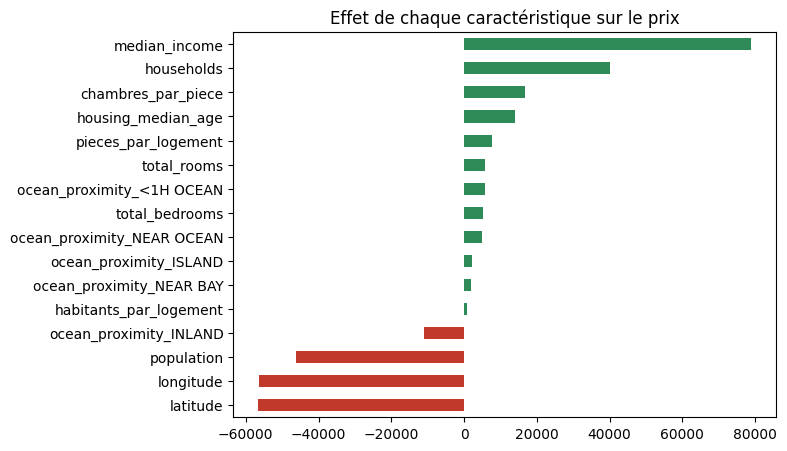

In [5]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

modele = make_pipeline(StandardScaler(), LinearRegression())
modele.fit(X_app, y_app)
pred = modele.predict(X_test)

print(f"MAE  : {mean_absolute_error(y_test, pred):,.0f} $   (l'erreur moyenne)")
print(f"RMSE : {mean_squared_error(y_test, pred) ** 0.5:,.0f} $   (punit plus les grosses erreurs)")
print(f"R²   : {r2_score(y_test, pred):.3f}   (1 = parfait, 0 = nul)")

coefs = pd.Series(modele[-1].coef_, index=X.columns).sort_values()
coefs.plot.barh(figsize=(7, 5), color=["#c0392b" if c < 0 else "#2e8b57" for c in coefs])
plt.title("Effet de chaque caractéristique sur le prix")
plt.show()

## 6. La validation croisée : 5 découpages pour un score plus sûr
On coupe les données d'apprentissage en 5 parts. Chaque part sert une fois de test. On fait la moyenne des 5 notes.

In [6]:
from sklearn.model_selection import cross_val_score

rmse_cv = -cross_val_score(make_pipeline(StandardScaler(), LinearRegression()), X_app, y_app,
                           cv=5, scoring="neg_root_mean_squared_error")
print("RMSE des 5 découpages :", rmse_cv.round(0))
print(f"Moyenne : {rmse_cv.mean():,.0f} $ | écart-type : {rmse_cv.std():,.0f} $ (petit = modèle stable)")

RMSE des 5 découpages : [68044. 66595. 66935. 66857. 70813.]
Moyenne : 67,849 $ | écart-type : 1,563 $ (petit = modèle stable)


## 7. L'ACP : résumer les colonnes en moins de colonnes
On cherche combien de colonnes résumées il faut pour garder 95 % de l'information, puis on regarde si le modèle fait mieux.

In [7]:
from sklearn.decomposition import PCA

acp = make_pipeline(StandardScaler(), PCA()).fit(X_app)
cumul = acp[-1].explained_variance_ratio_.cumsum()
k = int(np.argmax(cumul >= 0.95) + 1)
print(f"Il faut {k} composantes sur {X.shape[1]} pour garder 95 % de l'information.")

s = -cross_val_score(make_pipeline(StandardScaler(), PCA(n_components=k), LinearRegression()),
                     X_app, y_app, cv=5, scoring="neg_root_mean_squared_error")
print(f"Avec ACP : RMSE {s.mean():,.0f} $ | Sans ACP : RMSE {rmse_cv.mean():,.0f} $")

Il faut 10 composantes sur 16 pour garder 95 % de l'information.
Avec ACP : RMSE 79,873 $ | Sans ACP : RMSE 67,849 $


## 8. Comparaison avec un Random Forest
200 arbres de décision qui font chacun une prédiction. On prend la **moyenne** des 200 prix. Environ 30 secondes.

In [8]:
from sklearn.ensemble import RandomForestRegressor

foret = RandomForestRegressor(n_estimators=200, min_samples_leaf=2, random_state=42, n_jobs=-1)
foret.fit(X_app, y_app)
pred_foret = foret.predict(X_test)
print(f"Random Forest -> RMSE : {mean_squared_error(y_test, pred_foret) ** 0.5:,.0f} $ | R² : {r2_score(y_test, pred_foret):.3f}")

Random Forest -> RMSE : 49,672 $ | R² : 0.812


## À retenir pour l'entretien
- **Données :** 20 640 quartiers de Californie. On prédit le **prix médian** : c'est une **régression**.
- **Exploration :** le **revenu** est le plus lié au prix (0,69), l'**océan** double le prix, les prix sont **plafonnés à 500 001 $**.
- **Nettoyage :** cases vides remplies avec la **médiane**, texte transformé en 0/1 (**one-hot**), nouvelles colonnes **par logement**.
- **Régression linéaire :** R² ≈ **0,6** (elle explique 60 % des variations du prix), RMSE ≈ **68 000 $** en validation croisée.
- **L'ACP** réduit les colonnes, mais **n'améliore pas** le résultat.
- **Le Random Forest** fait mieux (R² ≈ **0,81**) : la relation n'est pas une simple droite.
- **Limite :** le modèle ne peut pas prédire au-dessus de **500 001 $**.

> « J'ai prédit le prix des logements de 20 640 quartiers de Californie. Après exploration et nettoyage, une régression linéaire explique environ 60 % des variations du prix, avec une erreur d'environ 68 000 dollars en validation croisée. L'ACP réduit le nombre de variables sans améliorer le résultat, et un Random Forest monte à un R² de 0,81, ce qui montre que la relation n'est pas linéaire. »